## FIGURE 1

In [1]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt # type: ignore
from matplotlib import cm, gridspec # type: ignore
import matplotlib.colors as mcolors

In [2]:
path_eco='data/ECOCLIM_surf.nc'
path_oshd='data/FSM_all.nc'
ds_meb=xr.open_dataset(path_eco)
ds_fsm=xr.open_dataset(path_oshd,decode_times=True)

xx,yy=ds_fsm.xx.values,ds_fsm.yy.values
latitude,longitude=ds_fsm.xx,ds_fsm.yy
X, Y = np.meshgrid(latitude, longitude)
h_veg=ds_meb.H_VEG.values.reshape(len(yy),len(xx))
LAI=ds_meb.LAI.values.reshape(len(yy),len(xx))
vegtype1=ds_meb.VEGTYPE1.values.reshape(len(yy),len(xx))
ds_meb=ds_meb.assign_coords(  ## on rajoute ces trois variables mais reshaper pour que ça matche avec fsm 
xx=('xx',xx), 
yy=('yy',yy)
)
ds_meb['lai']=(('yy','xx'),LAI)
ds_meb['h_veg']=(('yy','xx'),h_veg)
ds_meb['vegtype1']=(('yy','xx'),vegtype1)


C:\Users\mazzottg\AppData\Local\Temp\ipykernel_29280\2634382850.py:8: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('terrain').copy()


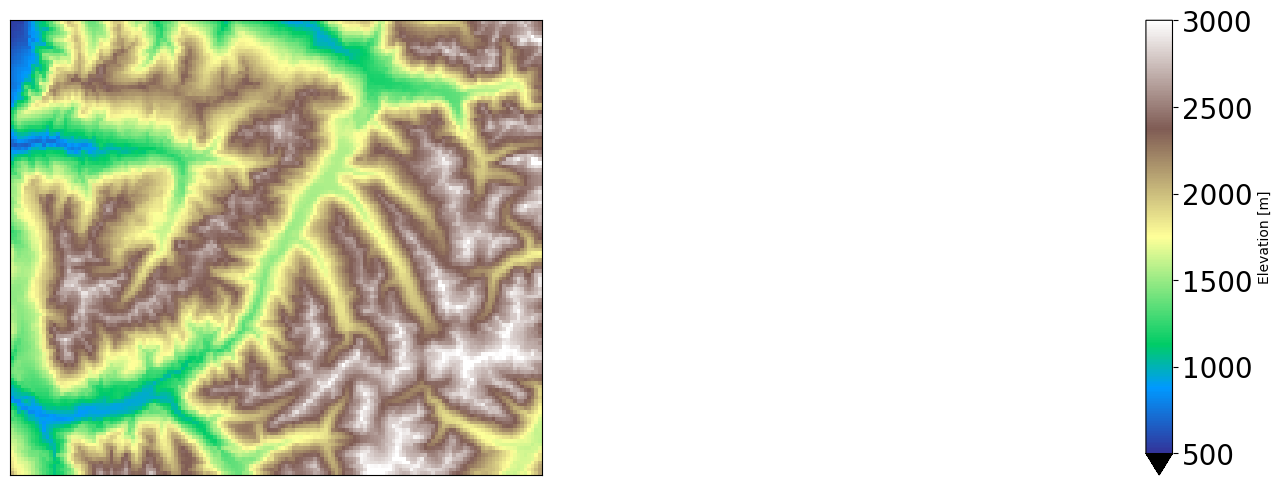

In [11]:
vmin = 500
vmax = 3000

fig = plt.figure(figsize=(30/2, 15/2.54))
gs = gridspec.GridSpec(1, 3, width_ratios=[1, 1, 0.05], wspace=0.1) ## setting pour avoir de l'espace entre les deux figures

# Colormap
cmap = cm.get_cmap('terrain').copy()
cmap.set_under(color='black')

#LAI ECOCLIMAP
ax1 = fig.add_subplot(gs[0])
mesh1 = ax1.pcolormesh(latitude, longitude, ds_fsm.dem, cmap=cmap, vmin=vmin, vmax=vmax)

ax1.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)

# Colorbar commune basée sur un ScalarMappable
from matplotlib.cm import ScalarMappable # type: ignore
sm = ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=vmin, vmax=vmax))

cax = fig.add_subplot(gs[2])
cbar = fig.colorbar(sm, cax=cax, extend='min')
cbar.set_label('Elevation [m]')
cbar.ax.tick_params(labelsize=20)

plt.show()

C:\Users\mazzottg\AppData\Local\Temp\ipykernel_29280\496421890.py:8: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('gist_earth_r').copy()


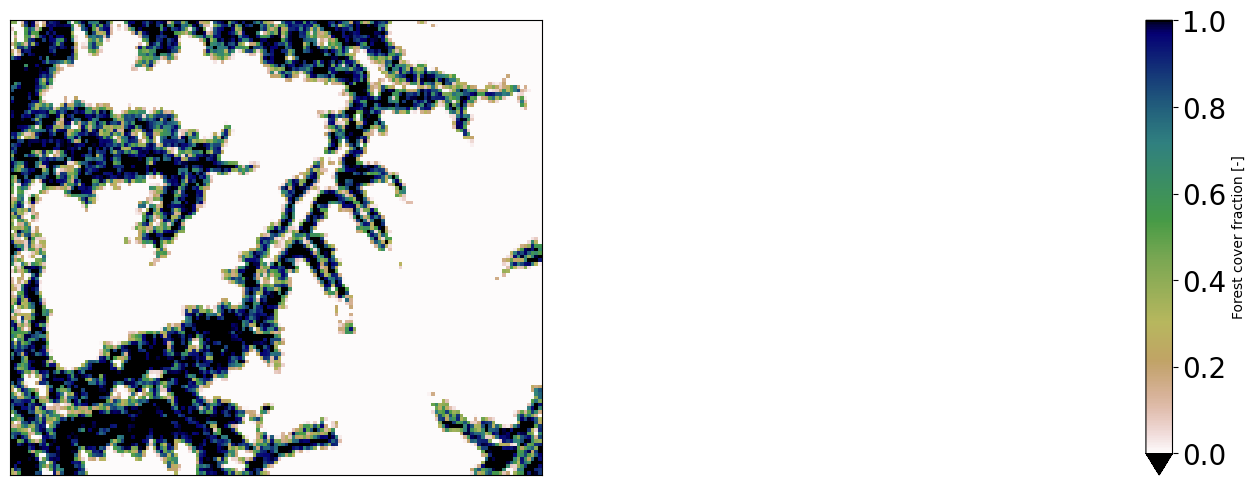

In [12]:
# Forest cover fraction map -> potentially to add to appendix
vmin = 0
vmax = 1

fig = plt.figure(figsize=(30/2, 15/2.54))
gs = gridspec.GridSpec(1, 3, width_ratios=[1, 1, 0.05], wspace=0.1) ## setting pour avoir de l'espace entre les deux figures

# Colormap
cmap = cm.get_cmap('gist_earth_r').copy()
cmap.set_under(color='black')

#LAI ECOCLIMAP
ax1 = fig.add_subplot(gs[0])
mesh1 = ax1.pcolormesh(latitude, longitude, ds_fsm.forest, cmap=cmap, vmin=vmin, vmax=vmax)

ax1.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)

# Colorbar commune basée sur un ScalarMappable
from matplotlib.cm import ScalarMappable # type: ignore
sm = ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=vmin, vmax=vmax))

cax = fig.add_subplot(gs[2])
cbar = fig.colorbar(sm, cax=cax, extend='min')
cbar.set_label('Forest cover fraction [-]')
cbar.ax.tick_params(labelsize=20)

plt.show()

C:\Users\mazzottg\AppData\Local\Temp\ipykernel_86804\791177229.py:8: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('YlGnBu').copy()


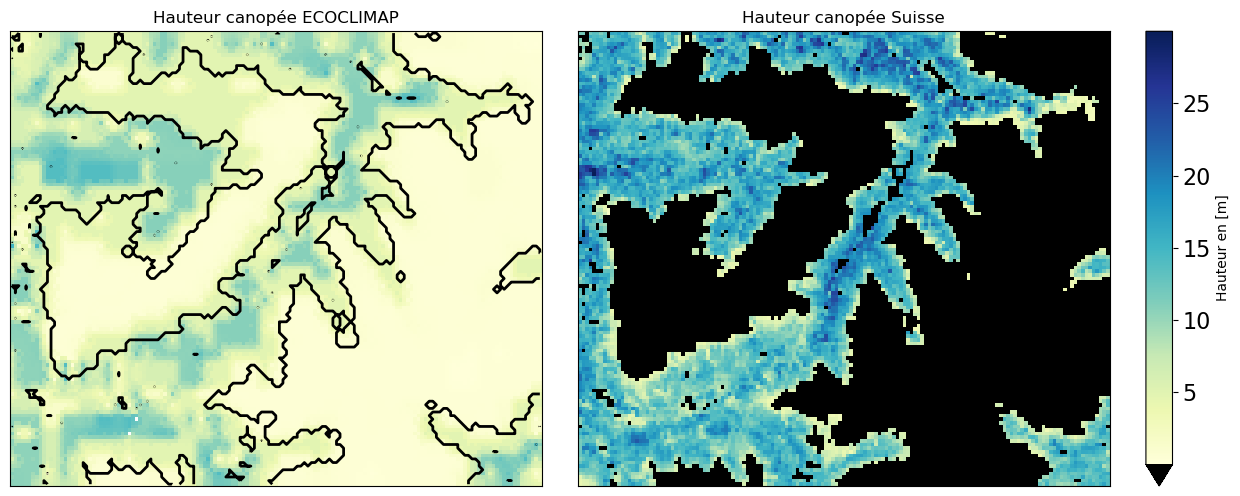

In [ ]:
vmin = 0.01
vmax = max(ds_meb.h_veg.max().values, ds_fsm.hcan.max().values) ## on recupére les bornes min et max 

fig = plt.figure(figsize=(30/2, 15/2.54))
gs = gridspec.GridSpec(1, 3, width_ratios=[1, 1, 0.05], wspace=0.1) ## setting pour avoir de l'espace entre les deux figures

# Colormap
cmap = cm.get_cmap('YlGnBu').copy()
cmap.set_under(color='black')

#LAI ECOCLIMAP
ax1 = fig.add_subplot(gs[0])
mesh1 = ax1.pcolormesh(latitude, longitude, ds_meb.h_veg, cmap=cmap, vmin=vmin, vmax=vmax)
contour_0 = ax1.contour(latitude, longitude, ds_fsm.hcan, levels=[0.001], colors='black', linewidths=2)
# ax1.clabel(contour_0, inline=True, fontsize=15, fmt="Hveg Suisse = 0")
ax1.set_title('Hauteur canopée ECOCLIMAP')

# LAI VEGE Suisse
ax2 = fig.add_subplot(gs[1])
mesh2 = ax2.pcolormesh(latitude, longitude, ds_fsm.hcan, cmap=cmap, vmin=vmin, vmax=vmax)
ax2.set_title('Hauteur canopée Suisse')


for ax in [ax1, ax2]:
    ax.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)

# Colorbar commune basée sur un ScalarMappable
from matplotlib.cm import ScalarMappable # type: ignore
sm = ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=vmin, vmax=vmax))

cax = fig.add_subplot(gs[2])
cbar = fig.colorbar(sm, cax=cax, extend='min')
cbar.set_label('Hauteur en [m]')
cbar.ax.tick_params(labelsize=16)
plt.savefig("Hauteur_vege_EN_PDF.jpg")
plt.show()

C:\Users\mazzottg\AppData\Local\Temp\ipykernel_86804\3817771193.py:13: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('YlGn').copy()


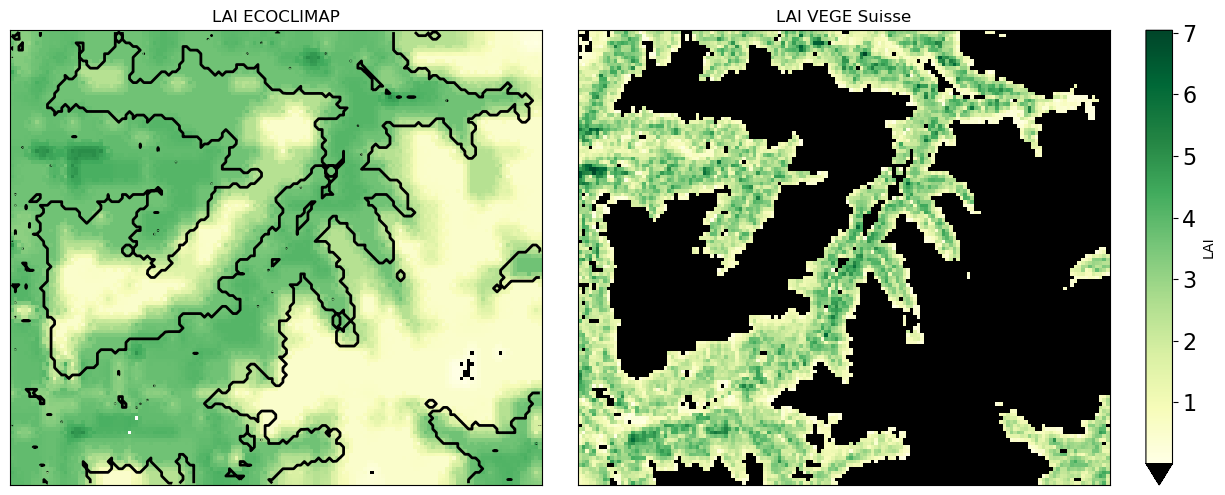

In [ ]:
import matplotlib.pyplot as plt # type: ignore
from matplotlib import cm, gridspec # type: ignore



vmin = 0.01
vmax = max(ds_meb.lai.max().values, ds_fsm.lai.max().values) ## on recupére les bornes min et max 

fig = plt.figure(figsize=(30/2, 15/2.54))
gs = gridspec.GridSpec(1, 3, width_ratios=[1, 1, 0.05], wspace=0.1) ## setting pour avoir de l'espace entre les deux figures

# Colormap
cmap = cm.get_cmap('YlGn').copy()
cmap.set_under(color='black')

#LAI ECOCLIMAP
ax1 = fig.add_subplot(gs[0])
mesh1 = ax1.pcolormesh(latitude, longitude, ds_meb.lai, cmap=cmap, vmin=vmin, vmax=vmax)
contour_0 = ax1.contour(latitude, longitude, ds_fsm.lai, levels=[0.001], colors='black', linewidths=2)
# ax1.clabel(contour_0, inline=True, fontsize=11, fmt="LAI-FSM = 0")
ax1.set_title('LAI ECOCLIMAP')

# LAI VEGE Suisse
ax2 = fig.add_subplot(gs[1])
mesh2 = ax2.pcolormesh(latitude, longitude, ds_fsm.lai, cmap=cmap, vmin=vmin, vmax=vmax)
ax2.set_title('LAI VEGE Suisse')


for ax in [ax1, ax2]:
    ax.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)

# Colorbar commune basée sur un ScalarMappable
from matplotlib.cm import ScalarMappable # type: ignore
sm = ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=vmin, vmax=vmax))

cax = fig.add_subplot(gs[2])
cbar = fig.colorbar(sm, cax=cax, extend='min')
cbar.set_label('LAI')
cbar.ax.tick_params(labelsize=16)
# plt.savefig("/home/vaccarof/Bureau/figures-finales/LAI_EN_PDF.pdf")
plt.show()

Text(0, 0.5, 'Frequency')

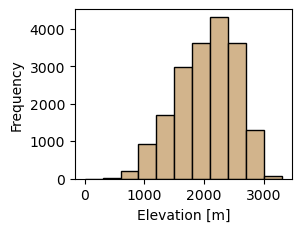

In [22]:
# Define custom bin edges
bin_edges = np.arange(000, 3501, 300)
elev = ds_fsm['dem'].values.flatten()
fig, ax = plt.subplots(1, 1, figsize=(2.8, 2.2), sharex=True)

# Plot quantile envelopes
ax.hist(elev, bins=bin_edges, color='tan', edgecolor='k')

# ax.legend()
ax.tick_params(labelsize=10)

ax.set_xlabel('Elevation [m]')
ax.set_ylabel('Frequency')


Text(0, 0.5, 'Frequency')

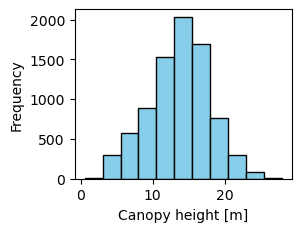

In [21]:
# Define custom bin edges
bin_edges = np.arange(0.5, 30.1, 2.5)
elev = ds_fsm['hcan'].values.flatten()
# Plot using matplotlib
fig, ax = plt.subplots(1, 1, figsize=(2.8, 2.2), sharex=True)

# Plot quantile envelopes
ax.hist(elev, bins=bin_edges, color='skyblue', edgecolor='k')

# ax.legend()
ax.tick_params(labelsize=10)

ax.set_xlabel('Canopy height [m]')
ax.set_ylabel('Frequency')

Text(0, 0.5, 'Frequency')

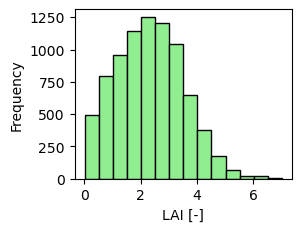

In [17]:
# Define custom bin edges
bin_edges = np.arange(0.01, 7.1,0.5)
lai= ds_fsm['lai'].values.flatten()

# Plot using matplotlib
fig, ax = plt.subplots(1, 1, figsize=(2.8, 2.2), sharex=True)

# Plot quantile envelopes
ax.hist(lai, bins=bin_edges, color='lightgreen', edgecolor='k')

# ax.legend()
ax.tick_params(labelsize=10)

ax.set_xlabel('LAI [-]')
ax.set_ylabel('Frequency')

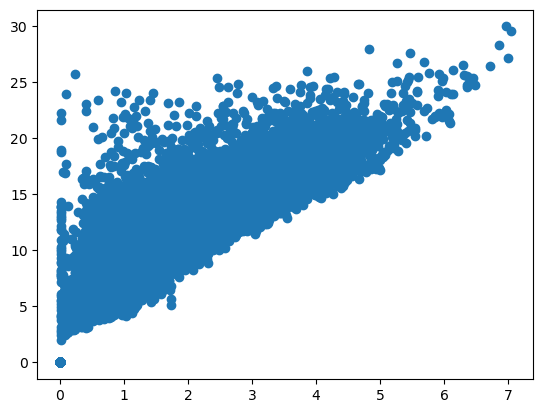

In [5]:
plt.scatter(ds_fsm['lai'].values.flatten(),ds_fsm['hcan'].values.flatten())

In [6]:
mask = ds_fsm['forest'].values.flatten() >= 0.1
laidata=ds_fsm['lai'].values.flatten()[mask]
hcandata=ds_fsm['hcan'].values.flatten()[mask]
cc = np.corrcoef(laidata,hcandata,rowvar=False)
cc


array([[1.        , 0.78294655],
       [0.78294655, 1.        ]])

In [ ]:
### POLARPLOT OF PHYSIOGRAPHIC VARIABLES 
altitudes = ds_fsm['dem'].values.flatten() ## On récupére les données d'altitude
aspect = ds_fsm['aspect'].values.flatten()

## On définit les cadrants
angle = np.array([22.5, 67.5, 112.5, 157.5, 202.5, 247.5, 292.5, 337.5])  ## ne pas modifier (Angles pour avoir 8 cadrants)
alt = np.arange(600, 2801, 300)   ## à modifier si on veut aller de 500 à 3500m

# Matrice pour stocker la moyenne de SWE par alt et orientation
SWE_matrix = np.zeros((len(alt)-1,len(angle)))
variable = ds_fsm["lai"].values.flatten() 

variable = xr.where(ds_fsm["dem"].values > 0, 1, 0).flatten() # dummy to just count cells


for i in range(len(alt)-1):# on se balade dans les altitudes
    for j in range(len(angle)): #on se balade dans les angles on part de 1 car le secteur nord est traité aprés
        if j == 0 :
            mask = (
                (altitudes >= alt[i]) & (altitudes < alt[i + 1]) & 
                ((aspect >= 337.5) | (aspect < 22.5))) 
        else :
            mask = (
                (altitudes >= alt[i]) & (altitudes < alt[i + 1]) & 
                (aspect >= angle[j-1]) & (aspect < angle[j]))
            
        SWE_values = variable[mask]
        SWE_matrix[i, j] = np.nanmean(SWE_values) if SWE_values.size > 0 else np.nan ##On moyenne en ignorant les nan et si pas de de valeur on rempli avec des nan 
        SWE_matrix[i, j]=np.count_nonzero(~np.isnan(SWE_values)) ## à utiliser si on veut le nombre exemple classe de LAI


np.max(SWE_matrix)

np.float64(633.0)

C:\Users\mazzottg\AppData\Local\Temp\ipykernel_21216\2727625634.py:29: RuntimeWarning: Mean of empty slice
  SWE_matrix[i, j] = np.nanmean(SWE_values) #if SWE_values.size > 0 else np.nan ##On moyenne en ignorant les nan et si pas de de valeur on rempli avec des nan


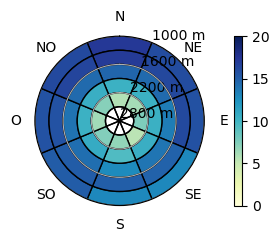

In [9]:
### POLARPLOT OF PHYSIOGRAPHIC VARIABLES 
altitudes = ds_fsm['dem'].values.flatten() ## On récupére les données d'altitude
aspect = ds_fsm['aspect'].values.flatten()
forest = ds_fsm["forest"].values.flatten()

## On définit les cadrants
angle = np.array([22.5, 67.5, 112.5, 157.5, 202.5, 247.5, 292.5, 337.5])  ## ne pas modifier (Angles pour avoir 8 cadrants)
alt = np.arange(1000, 2801, 300)   ## à modifier si on veut aller de 500 à 3500m

# Matrice pour stocker la moyenne de SWE par alt et orientation
SWE_matrix = np.zeros((len(alt)-1,len(angle)))
variable = ds_fsm["hcan"].values.flatten() 

#variable = xr.where(ds_fsm["lai"].values > 0, 1, 0).flatten() # dummy to just count cells


for i in range(len(alt)-1):# on se balade dans les altitudes
    for j in range(len(angle)): #on se balade dans les angles on part de 1 car le secteur nord est traité aprés
        if j == 0 :
            mask = (
                (altitudes >= alt[i]) & (altitudes < alt[i + 1]) & 
                ((aspect >= 337.5) | (aspect < 22.5)) & (forest >= 0.1)) 
        else :
            mask = (
                (altitudes >= alt[i]) & (altitudes < alt[i + 1]) & 
                (aspect >= angle[j-1]) & (aspect < angle[j]) & (forest >= 0.1))
            
        SWE_values = variable[mask]
        SWE_matrix[i, j] = np.nanmean(SWE_values) #if SWE_values.size > 0 else np.nan ##On moyenne en ignorant les nan et si pas de de valeur on rempli avec des nan 
        #SWE_matrix[i, j]=  np.count_nonzero(~np.isnan(SWE_values)) ## à utiliser si on veut le nombre exemple classe de LAI
        #SWE_matrix[i, j] = np.nansum(SWE_values)


fig,ax = plt.subplots(1,1,figsize=(3.8,2.2),subplot_kw={'projection':'polar'})
norm=mcolors.Normalize(vmin=0,vmax=20)
cmap=plt.get_cmap('YlGnBu')
#cmap=plt.get_cmap('turbo')

for i in range(len(alt)-1):
    for j in range(len(angle)):
        if j==0: ## secteur Nord
            theta1, theta2=np.radians([337.5,22.5])
            r1, r2 = alt[i], alt[i + 1]

            ax.bar(0,  # Position angulaire centrale
            r2 - r1,  # Largeur radiale
            width=theta2 + theta2 , # Largeur angulaire
            bottom=r1,  # Début de l'anneau
            color=cmap(norm(SWE_matrix[i, j] )),  
            edgecolor='black')
        else:
            theta1, theta2 = np.radians([angle[j-1], angle[j]])
            r1, r2 = alt[i], alt[i + 1]
            ax.bar((theta1 + theta2) / 2,  
            r2 - r1,  
            width=theta2 - theta1,  
            bottom=r1,  
            color=cmap(norm(SWE_matrix[i, j])),  
            edgecolor='black')

        
   # ax.set_ylim(2200, 1000) # Permet de commencer par le bas et finir par le haut
ax.set_ylim(2800, 1000) # Permet de commencer par le bas et finir par le haut
ax.set_theta_zero_location('N')  # On place le Nord en haut
ax.set_theta_direction(-1)  # Sens horaire

# Paramétres pour afficher les orientations
label=['N','NE','E','SE','S','SO','O','NO']
angles=np.array([0,45,90,135,180,225,270,315])
ax.set_xticks(np.radians(angles))
ax.set_xticklabels(label,fontsize=10)
ax.grid(False,axis='x')## enleve la barre
# Ajouter les cercles d'altitude
# rticks =[2200,1800,1400,1000]
rticks =[2800,2200,1600,1000]
ax.set_yticks(rticks)
ax.set_yticklabels([f"{int(alt)} m" for alt in rticks],fontsize=10)
# Paramétres pour la colorbar
sm = plt.cm.ScalarMappable(cmap=cmap)
sm.set_array(SWE_matrix)
cbar = fig.colorbar(sm, ax=ax, orientation='vertical',fraction=0.036,pad=0.1)
cbar.ax.tick_params(labelsize=10)
sm.set_clim(0,20)

C:\Users\mazzottg\AppData\Local\Temp\ipykernel_21216\1902839323.py:31: RuntimeWarning: Mean of empty slice
  SWE_matrix[i, j] = np.nanmean(SWE_values) #if SWE_values.size > 0 else np.nan ##On moyenne en ignorant les nan et si pas de de valeur on rempli avec des nan


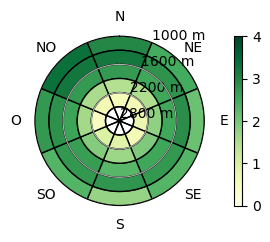

In [ ]:
### POLARPLOT OF PHYSIOGRAPHIC VARIABLES 
altitudes = ds_fsm['dem'].values.flatten() ## On récupére les données d'altitude
aspect = ds_fsm['aspect'].values.flatten()
forest = ds_fsm["forest"].values.flatten()

ask = ds_fsm['forest'].values.flatten() >= 0.1

## On définit les cadrants
angle = np.array([22.5, 67.5, 112.5, 157.5, 202.5, 247.5, 292.5, 337.5])  ## ne pas modifier (Angles pour avoir 8 cadrants)
alt = np.arange(1000, 2801, 300)   ## à modifier si on veut aller de 500 à 3500m

# Matrice pour stocker la moyenne de SWE par alt et orientation
SWE_matrix = np.zeros((len(alt)-1,len(angle)))
variable = ds_fsm["lai"].values.flatten() 

#variable = xr.where(ds_fsm["lai"].values > 0, 1, 0).flatten() # dummy to just count cells


for i in range(len(alt)-1):# on se balade dans les altitudes
    for j in range(len(angle)): #on se balade dans les angles on part de 1 car le secteur nord est traité aprés
        if j == 0 :
            mask = (
                (altitudes >= alt[i]) & (altitudes < alt[i + 1]) & 
                ((aspect >= 337.5) | (aspect < 22.5)) & (forest >= 0.1)) 
        else :
            mask = (
                (altitudes >= alt[i]) & (altitudes < alt[i + 1]) & 
                (aspect >= angle[j-1]) & (aspect < angle[j]) & (forest >= 0.1))
            
        SWE_values = variable[mask]
        SWE_matrix[i, j] = np.nanmean(SWE_values) #if SWE_values.size > 0 else np.nan ##On moyenne en ignorant les nan et si pas de de valeur on rempli avec des nan 
        #SWE_matrix[i, j]=  np.count_nonzero(~np.isnan(SWE_values)) ## à utiliser si on veut le nombre exemple classe de LAI
        #SWE_matrix[i, j] = np.nansum(SWE_values)


fig,ax = plt.subplots(1,1,figsize=(3.8,2.2),subplot_kw={'projection':'polar'})
norm=mcolors.Normalize(vmin=0,vmax=4)
cmap=plt.get_cmap('YlGn')
#cmap=plt.get_cmap('turbo')

for i in range(len(alt)-1):
    for j in range(len(angle)):
        if j==0: ## secteur Nord
            theta1, theta2=np.radians([337.5,22.5])
            r1, r2 = alt[i], alt[i + 1]

            ax.bar(0,  # Position angulaire centrale
            r2 - r1,  # Largeur radiale
            width=theta2 + theta2 , # Largeur angulaire
            bottom=r1,  # Début de l'anneau
            color=cmap(norm(SWE_matrix[i, j] )),  
            edgecolor='black')
        else:
            theta1, theta2 = np.radians([angle[j-1], angle[j]])
            r1, r2 = alt[i], alt[i + 1]
            ax.bar((theta1 + theta2) / 2,  
            r2 - r1,  
            width=theta2 - theta1,  
            bottom=r1,  
            color=cmap(norm(SWE_matrix[i, j])),  
            edgecolor='black')

        
   # ax.set_ylim(2200, 1000) # Permet de commencer par le bas et finir par le haut
ax.set_ylim(2800, 1000) # Permet de commencer par le bas et finir par le haut
ax.set_theta_zero_location('N')  # On place le Nord en haut
ax.set_theta_direction(-1)  # Sens horaire

# Paramétres pour afficher les orientations
label=['N','NE','E','SE','S','SO','O','NO']
angles=np.array([0,45,90,135,180,225,270,315])
ax.set_xticks(np.radians(angles))
ax.set_xticklabels(label,fontsize=10)
ax.grid(False,axis='x')## enleve la barre
# Ajouter les cercles d'altitude
# rticks =[2200,1800,1400,1000]
rticks =[2800,2200,1600,1000]
ax.set_yticks(rticks)
ax.set_yticklabels([f"{int(alt)} m" for alt in rticks],fontsize=10)
# Paramétres pour la colorbar
unite = 'days'
sm = plt.cm.ScalarMappable(cmap=cmap)
sm.set_array(SWE_matrix)
cbar = fig.colorbar(sm, ax=ax, orientation='vertical',fraction=0.036,pad=0.1)
cbar.ax.tick_params(labelsize=10)
sm.set_clim(0,4)


In [6]:
### POLARPLOT OF PHYSIOGRAPHIC VARIABLES 
altitudes = ds_fsm['dem'].values.flatten() ## On récupére les données d'altitude
aspect = ds_fsm['aspect'].values.flatten()
forest = ds_fsm["forest"].values.flatten()

ask = ds_fsm['forest'].values.flatten() >= 0.1

## On définit les cadrants
angle = np.array([22.5, 67.5, 112.5, 157.5, 202.5, 247.5, 292.5, 337.5])  ## ne pas modifier (Angles pour avoir 8 cadrants)
alt = np.arange(1000, 2801, 300)   ## à modifier si on veut aller de 500 à 3500m

# Matrice pour stocker la moyenne de SWE par alt et orientation
SWE_matrix = np.zeros((len(alt)-1,len(angle)))
variable = ds_fsm["lai"].values.flatten() 

variable = xr.where(ds_fsm["dem"].values > 0, 1, 0).flatten() # dummy to just count cells

for i in range(len(alt)-1):# on se balade dans les altitudes
    for j in range(len(angle)): #on se balade dans les angles on part de 1 car le secteur nord est traité aprés
        if j == 0 :
            mask = (
                (altitudes >= alt[i]) & (altitudes < alt[i + 1]) & 
                ((aspect >= 337.5) | (aspect < 22.5)) & (forest >= 0.1)) 
        else :
            mask = (
                (altitudes >= alt[i]) & (altitudes < alt[i + 1]) & 
                (aspect >= angle[j-1]) & (aspect < angle[j]) & (forest >= 0.1))
            
        SWE_values = variable[mask]
        SWE_matrix[i, j] = np.nansum(SWE_values) #if SWE_values.size > 0 else np.nan ##On moyenne en ignorant les nan et si pas de de valeur on rempli avec des nan 
        #SWE_matrix[i, j]=  np.count_nonzero(~np.isnan(SWE_values)) ## à utiliser si on veut le nombre exemple classe de LAI
        #SWE_matrix[i, j] = np.nansum(SWE_values)


In [7]:
SWE_matrix

array([[228., 149.,  33.,  55., 186., 170.,  87., 114.],
       [289., 280., 163., 155., 266., 264., 291., 266.],
       [358., 399., 231., 308., 313., 333., 435., 353.],
       [176., 214.,  95., 138., 170., 184., 211., 160.],
       [  4.,   9.,   3.,   7.,  16.,   8.,   8.,   6.],
       [  0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.]])

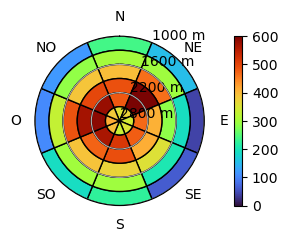

In [ ]:
### POLARPLOT OF PHYSIOGRAPHIC VARIABLES 
altitudes = ds_fsm['dem'].values.flatten() ## On récupére les données d'altitude
aspect = ds_fsm['aspect'].values.flatten()
forest = ds_fsm["forest"].values.flatten()

## On définit les cadrants
angle = np.array([22.5, 67.5, 112.5, 157.5, 202.5, 247.5, 292.5, 337.5])  ## ne pas modifier (Angles pour avoir 8 cadrants)
alt = np.arange(1000, 2801, 300)   ## à modifier si on veut aller de 500 à 3500m

# Matrice pour stocker la moyenne de SWE par alt et orientation
SWE_matrix = np.zeros((len(alt)-1,len(angle)))
variable = xr.where(ds_fsm["dem"].values > 0, 1, 0).flatten() # dummy to just count cells


for i in range(len(alt)-1):# on se balade dans les altitudes
    for j in range(len(angle)): #on se balade dans les angles on part de 1 car le secteur nord est traité aprés
        if j == 0 :
            mask = (
                (altitudes >= alt[i]) & (altitudes < alt[i + 1]) & 
                ((aspect >= 337.5) | (aspect < 22.5))) 
        else :
            mask = (
                (altitudes >= alt[i]) & (altitudes < alt[i + 1]) & 
                (aspect >= angle[j-1]) & (aspect < angle[j]) )
            
        SWE_values = variable[mask]
        SWE_matrix[i, j] = np.nansum(SWE_values) #if SWE_values.size > 0 else np.nan ##On moyenne en ignorant les nan et si pas de de valeur on rempli avec des nan 
        #SWE_matrix[i, j]=  np.count_nonzero(~np.isnan(SWE_values)) ## à utiliser si on veut le nombre exemple classe de LAI
        #SWE_matrix[i, j] = np.nansum(SWE_values)


fig,ax = plt.subplots(1,1,figsize=(3.8,2.2),subplot_kw={'projection':'polar'})
norm=mcolors.Normalize(vmin=0,vmax=600)
cmap=plt.get_cmap('YlGn')
cmap=plt.get_cmap('turbo')

for i in range(len(alt)-1):
    for j in range(len(angle)):
        if j==0: ## secteur Nord
            theta1, theta2=np.radians([337.5,22.5])
            r1, r2 = alt[i], alt[i + 1]

            ax.bar(0,  # Position angulaire centrale
            r2 - r1,  # Largeur radiale
            width=theta2 + theta2 , # Largeur angulaire
            bottom=r1,  # Début de l'anneau
            color=cmap(norm(SWE_matrix[i, j] )),  
            edgecolor='black')
        else:
            theta1, theta2 = np.radians([angle[j-1], angle[j]])
            r1, r2 = alt[i], alt[i + 1]
            ax.bar((theta1 + theta2) / 2,  
            r2 - r1,  
            width=theta2 - theta1,  
            bottom=r1,  
            color=cmap(norm(SWE_matrix[i, j])),  
            edgecolor='black')

        
   # ax.set_ylim(2200, 1000) # Permet de commencer par le bas et finir par le haut
ax.set_ylim(2800, 1000) # Permet de commencer par le bas et finir par le haut
ax.set_theta_zero_location('N')  # On place le Nord en haut
ax.set_theta_direction(-1)  # Sens horaire

# Paramétres pour afficher les orientations
label=['N','NE','E','SE','S','SO','O','NO']
angles=np.array([0,45,90,135,180,225,270,315])
ax.set_xticks(np.radians(angles))
ax.set_xticklabels(label,fontsize=10)
ax.grid(False,axis='x')## enleve la barre
# Ajouter les cercles d'altitude
# rticks =[2200,1800,1400,1000]
rticks =[2800,2200,1600,1000]
ax.set_yticks(rticks)
ax.set_yticklabels([f"{int(alt)} m" for alt in rticks],fontsize=10)
# Paramétres pour la colorbar
unite = 'days'
sm = plt.cm.ScalarMappable(cmap=cmap)
sm.set_array(SWE_matrix)
cbar = fig.colorbar(sm, ax=ax, orientation='vertical',fraction=0.036,pad=0.1)
cbar.ax.tick_params(labelsize=10)
sm.set_clim(0,600)

In [15]:
SWE_matrix

array([[238., 153.,  40.,  63., 224., 189., 105., 119.],
       [302., 296., 192., 206., 296., 298., 329., 288.],
       [394., 462., 284., 354., 371., 390., 486., 389.],
       [488., 606., 410., 412., 490., 472., 568., 498.],
       [481., 633., 467., 478., 516., 563., 587., 578.],
       [355., 371., 343., 352., 333., 394., 414., 383.]])

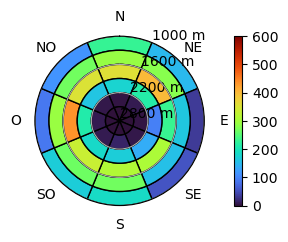

In [22]:
### POLARPLOT OF PHYSIOGRAPHIC VARIABLES 
altitudes = ds_fsm['dem'].values.flatten() ## On récupére les données d'altitude
aspect = ds_fsm['aspect'].values.flatten()
forest = ds_fsm["forest"].values.flatten()

## On définit les cadrants
angle = np.array([22.5, 67.5, 112.5, 157.5, 202.5, 247.5, 292.5, 337.5])  ## ne pas modifier (Angles pour avoir 8 cadrants)
alt = np.arange(1000, 2801, 300)   ## à modifier si on veut aller de 500 à 3500m

# Matrice pour stocker la moyenne de SWE par alt et orientation
SWE_matrix = np.zeros((len(alt)-1,len(angle)))
variable = xr.where(ds_fsm["forest"].values >= 0.1, 1, 0).flatten() # dummy to just count cells


for i in range(len(alt)-1):# on se balade dans les altitudes
    for j in range(len(angle)): #on se balade dans les angles on part de 1 car le secteur nord est traité aprés
        if j == 0 :
            mask = (
                (altitudes >= alt[i]) & (altitudes < alt[i + 1]) & 
                ((aspect >= 337.5) | (aspect < 22.5))) 
        else :
            mask = (
                (altitudes >= alt[i]) & (altitudes < alt[i + 1]) & 
                (aspect >= angle[j-1]) & (aspect < angle[j]) )
            
        SWE_values = variable[mask]
        SWE_matrix[i, j] = np.nansum(SWE_values) #if SWE_values.size > 0 else np.nan ##On moyenne en ignorant les nan et si pas de de valeur on rempli avec des nan 
        #SWE_matrix[i, j]=  np.count_nonzero(~np.isnan(SWE_values)) ## à utiliser si on veut le nombre exemple classe de LAI
        #SWE_matrix[i, j] = np.nansum(SWE_values)


fig,ax = plt.subplots(1,1,figsize=(3.8,2.2),subplot_kw={'projection':'polar'})
norm=mcolors.Normalize(vmin=0,vmax=600)
cmap=plt.get_cmap('turbo')

for i in range(len(alt)-1):
    for j in range(len(angle)):
        if j==0: ## secteur Nord
            theta1, theta2=np.radians([337.5,22.5])
            r1, r2 = alt[i], alt[i + 1]

            ax.bar(0,  # Position angulaire centrale
            r2 - r1,  # Largeur radiale
            width=theta2 + theta2 , # Largeur angulaire
            bottom=r1,  # Début de l'anneau
            color=cmap(norm(SWE_matrix[i, j] )),  
            edgecolor='black')
        else:
            theta1, theta2 = np.radians([angle[j-1], angle[j]])
            r1, r2 = alt[i], alt[i + 1]
            ax.bar((theta1 + theta2) / 2,  
            r2 - r1,  
            width=theta2 - theta1,  
            bottom=r1,  
            color=cmap(norm(SWE_matrix[i, j])),  
            edgecolor='black')

        
   # ax.set_ylim(2200, 1000) # Permet de commencer par le bas et finir par le haut
ax.set_ylim(2800, 1000) # Permet de commencer par le bas et finir par le haut
ax.set_theta_zero_location('N')  # On place le Nord en haut
ax.set_theta_direction(-1)  # Sens horaire

# Paramétres pour afficher les orientations
label=['N','NE','E','SE','S','SO','O','NO']
angles=np.array([0,45,90,135,180,225,270,315])
ax.set_xticks(np.radians(angles))
ax.set_xticklabels(label,fontsize=10)
ax.grid(False,axis='x')## enleve la barre
# Ajouter les cercles d'altitude
# rticks =[2200,1800,1400,1000]
rticks =[2800,2200,1600,1000]
ax.set_yticks(rticks)
ax.set_yticklabels([f"{int(alt)} m" for alt in rticks],fontsize=10)
# Paramétres pour la colorbar
unite = 'days'
sm = plt.cm.ScalarMappable(cmap=cmap)
sm.set_array(SWE_matrix)
cbar = fig.colorbar(sm, ax=ax, orientation='vertical',fraction=0.036,pad=0.1)
cbar.ax.tick_params(labelsize=10)
sm.set_clim(0,600)

In [20]:
SWE_matrix

array([[228., 149.,  33.,  55., 186., 170.,  87., 114.],
       [289., 280., 163., 155., 266., 264., 291., 266.],
       [358., 399., 231., 308., 313., 333., 435., 353.],
       [176., 214.,  95., 138., 170., 184., 211., 160.],
       [  4.,   9.,   3.,   7.,  16.,   8.,   8.,   6.],
       [  0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.]])